# Training Optimization and Model Selection - Dzifa, Avi, Erin, Aarabhi

**Archive of how the final model was chosen.** This notebook is not part of the pipeline: the final model is trained in `notebooks/pipeline/05_model_training_and_selection.ipynb`. All choices here were made on the 61-contract validation set.

**What's in it**
- Sections 6–7: RoBERTa vs Legal-BERT, a class-weighting grid (8 settings), focal loss and asymmetric loss (ASL), all at learning rate 2e-5 for 15 epochs
- Section 8: contract-level scores, per-category F1 and one global threshold for the strongest runs
- Section 9: Optuna tuning of the focal setup (8 trials) and a check with a second seed

**Result:** class weights gave the first big gain; the weightings and losses then performed within noise of each other (validation macro F1 0.604–0.634). Tuning the learning rate and training length gave the final model, `legal-bert-focal-optuna`: validation macro F1 0.662 (chunk-level) and 0.787 (contract-level), confirmed with a second seed (0.654 / 0.796). Details in section 11.

**How to run:** on Colab with a GPU (`RUN_MODE = "auto"` runs **full** on a GPU and **smoke**, a quick pipeline check on a tiny subset, on CPU). By default **Run all retrains nothing** and only shows the saved results (about 10 minutes): they are read from your Google Drive or, if missing, from `results/training/15ep/` in the repo. To retrain, add run names to `RUNS_TO_RUN` (about 14 minutes each on an A100) or set `RUN_OPTUNA` / `RUN_SEED_CHECK` to `True` in the settings cell.

## 0. Google Colab setup
On Colab: clones the repo, installs `requirements.txt`, mounts Google Drive (results are saved there). Does nothing elsewhere.

In [ ]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Break-Through-Tech/Accenture-1H-contract-review-challenge.git"
REPO_BRANCH = "main"
SAVE_TO_DRIVE = True                          # Colab only: keep results/checkpoints on Google Drive

if IN_COLAB:
    repo_dir = "/content/Accenture-1H-contract-review-challenge"
    if not os.path.exists(repo_dir):
        cloned = subprocess.run(["git", "clone", "--depth", "1", "-b", REPO_BRANCH, REPO_URL, repo_dir]).returncode == 0
        if not cloned:   # branch not on GitHub (yet): main has the same data files
            print(f"Branch {REPO_BRANCH} not found, cloning main instead.")
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, repo_dir], check=True)
    os.chdir(f"{repo_dir}/notebooks/experimentation/Transformer")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../../../requirements.txt"], check=True)
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
print("In Colab:", IN_COLAB, "| working dir:", os.getcwd())

Mounted at /content/drive
In Colab: True | working dir: /content/Accenture-1H-contract-review-challenge/notebooks


## 1. Setup

In [ ]:
import gc, json, re, shutil, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import transformers
from datasets import Dataset, DatasetDict, Features, Sequence, Value, load_from_disk, disable_progress_bars
from sklearn.metrics import average_precision_score, precision_recall_fscore_support
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)
from sklearn.metrics import f1_score, precision_recall_curve

transformers.logging.set_verbosity_error()   # hide the expected "newly initialized classifier" warning
disable_progress_bars()                       # keep tokenization output short
print("torch", torch.__version__, "| transformers", transformers.__version__)

torch 2.14.1+cu130 | transformers 4.57.6


All settings. Add or remove names in `RUNS_TO_RUN` to choose which runs to train in this session (finished runs are skipped).

In [ ]:
RUN_MODE = "auto"      # "auto" (full if a GPU is available, else smoke), "full", or "smoke"
SEED = 42
DATA_DIR = "../../../data/processed"

MODELS = {   # short tag -> Hugging Face model name
    "roberta": "roberta-base",
    "legal-bert": "nlpaueb/legal-bert-base-uncased",
}

# Runs. Each entry is one training run; its key is the run name (the folder name under results/ and models/).
#   model       : key of MODELS above
#   power, cap  : weighted loss. pos_weight = clip((negatives / positives) ** power, 1, cap). Leave both out for plain BCE.
# Name format for weighted runs: <model>-w-p<power>-c<cap>, e.g. legal-bert-w-p0.5-c20.
POWERS = [0.5, 0.75]
CAPS = [5, 7, 10, 20]
RUNS = {
    "roberta":             dict(model="roberta"),
    "legal-bert":          dict(model="legal-bert"),
    "legal-bert-weighted": dict(model="legal-bert", power=0.5, cap=10),   # first weighted run (same as legal-bert-w-p0.5-c10)
}
for p in POWERS:
    for c in CAPS:
        if (p, c) != (0.5, 10):
            RUNS[f"legal-bert-w-p{p}-c{c}"] = dict(model="legal-bert", power=p, cap=c)

# Other losses. loss="focal" (gamma; optional power/cap adds class weights) or loss="asl" (gamma_neg, gamma_pos, clip)
RUNS["legal-bert-focal-g2-p0.5-c10"] = dict(model="legal-bert", loss="focal", gamma=2, power=0.5, cap=10)
RUNS["legal-bert-asl"]               = dict(model="legal-bert", loss="asl", gamma_neg=4, gamma_pos=0, clip=0.05)

assert all(r["model"] in MODELS for r in RUNS.values())

# Which runs to train in this session. Empty = retrain nothing; Run all then only shows the saved results.
# The runs of this experiment (about 14 min each on an A100): "roberta", "legal-bert", "legal-bert-weighted", the 7 other
# "legal-bert-w-p<power>-c<cap>" runs, "legal-bert-focal-g2-p0.5-c10", "legal-bert-asl". Finished runs are skipped.
RUNS_TO_RUN = []
SKIP_FINISHED = True   # don't retrain a model whose summary.json already exists
RUN_OPTUNA = False      # True: run the Optuna study (section 9; 8 trials, about 2.5 hours on an A100). False: show the saved study
RUN_SEED_CHECK = False  # True: retrain the best Optuna settings with seed 43 (about 18 minutes on an A100). False: show the saved result

MAX_LENGTH = 512       # both models' input limit
OVERLAP = 128          # chunk overlap used in pipeline/02_data_tokenization_and_chunking.ipynb
THRESHOLD = 0.5        # decision threshold (fixed)
SELECT_METRIC = "macro_ap"   # validation metric used to choose the best epoch of each run (see section 5)
WINNER_METRIC = "macro_f1"   # validation metric used to choose the winning run (the project goal is macro F1)
SCORE_TEST_PER_RUN = False   # keep False: the test set is scored once, for the final model, in pipeline/05

FULL = dict(num_epochs=15, learning_rate=2e-5, effective_batch_size=16, max_length=MAX_LENGTH,
            warmup_ratio=0.1, weight_decay=0.01, subset=None)
SMOKE = dict(num_epochs=3, learning_rate=5e-5, effective_batch_size=16, max_length=128,
             warmup_ratio=0.1, weight_decay=0.01, subset={"train": 384, "validation": 128, "test": 128})

if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f"{DATA_DIR} not found. Run this notebook from the notebooks/experimentation/Transformer/ folder.")
set_seed(SEED)

## 2. GPU training environment
Checks the device and turns on mixed precision on GPU (bf16 if supported, else fp16). The per-step batch size depends on GPU memory; gradient accumulation keeps the **effective batch size at 16**.

In [ ]:
HAS_GPU = torch.cuda.is_available()
MODE = ("full" if HAS_GPU else "smoke") if RUN_MODE == "auto" else RUN_MODE
CFG = dict(FULL if MODE == "full" else SMOKE)

print("Python:", platform.python_version(), "| CPU cores:", os.cpu_count())
if HAS_GPU:
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1e9
    print(f"GPU: {props.name} | {vram_gb:.1f} GB | CUDA {torch.version.cuda}")
    USE_BF16 = torch.cuda.is_bf16_supported()
    USE_FP16 = not USE_BF16
    per_device = 16 if vram_gb >= 40 else 8 if vram_gb >= 14 else 4
else:
    print("GPU: none found. Training runs on CPU.")
    if IN_COLAB:
        print("  -> On Colab: Runtime > Change runtime type > T4 GPU (or better), then run all again.")
    USE_BF16 = USE_FP16 = False
    per_device = 8
if MODE == "full" and not HAS_GPU:
    print("WARNING: full mode on CPU will take many hours per epoch.")

# Make sure the device can actually run a computation
device = torch.device("cuda" if HAS_GPU else "cpu")
a = torch.randn(1024, 1024, device=device)
assert torch.isfinite(a @ a).all()

CFG["per_device_batch_size"] = min(per_device, CFG["effective_batch_size"])
CFG["grad_accum_steps"] = CFG["effective_batch_size"] // CFG["per_device_batch_size"]
print(f"Device check passed on {device}. Mode: {MODE} | precision: "
      f"{'bf16' if USE_BF16 else 'fp16' if USE_FP16 else 'fp32'} | batch {CFG['per_device_batch_size']} "
      f"x {CFG['grad_accum_steps']} accumulation = {CFG['effective_batch_size']}")

Python: 3.13.16 | CPU cores: 12
GPU: NVIDIA A100-SXM4-40GB | 42.4 GB | CUDA 13.0
Device check passed on cuda. Mode: full | precision: bf16 | batch 16 x 1 accumulation = 16


In [ ]:
# results/ is committed, models/ is not. Each run gets its own folder (e.g. 15ep). Smoke runs stay under models/.
RUN_NAME = f"{CFG['num_epochs']}ep"
OUTPUT_ROOT = "/content/drive/MyDrive/Accenture-1H-contract-review-challenge" if (IN_COLAB and SAVE_TO_DRIVE) else "../../.."
RESULTS_DIR = f"{OUTPUT_ROOT}/results/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke/results"
MODELS_DIR = f"{OUTPUT_ROOT}/models/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
EXP_TAG = "loss_and_tuning"
EXP_DIR = f"{RESULTS_DIR}/experiments"   # this notebook's comparison table and plot (kept apart from the pipeline's)
os.makedirs(EXP_DIR, exist_ok=True)
print("Results:", RESULTS_DIR, "\nCheckpoints:", MODELS_DIR)

Results: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/results/training/15ep 
Checkpoints: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep


In [ ]:
# Bring in finished results committed to the repo (results/training/15ep/), so the tables below work without the
# Google Drive that trained them. Files already in RESULTS_DIR are kept. Checkpoints are not in git (Drive only).
COMMITTED = f"../../../results/training/{RUN_NAME}"
if MODE == "full" and os.path.exists(COMMITTED):
    for entry in sorted(os.listdir(COMMITTED)):
        src, dst = f"{COMMITTED}/{entry}", f"{RESULTS_DIR}/{entry}"
        if not os.path.exists(dst):
            (shutil.copytree if os.path.isdir(src) else shutil.copy)(src, dst)
print(sorted(os.listdir(RESULTS_DIR)))

['legal-bert', 'legal-bert-weighted', 'roberta', 'legal-bert-w-p0.5-c20', 'legal-bert-w-p0.75-c10', 'legal-bert-w-p0.5-c5', 'legal-bert-w-p0.5-c7', 'legal-bert-w-p0.75-c7', 'legal-bert-w-p0.75-c20', 'legal-bert-focal-g2-p0.5-c10', 'legal-bert-asl', 'legal-bert-w-p0.5-c10-dorig-k1.0', 'legal-bert-w-p0.5-c10-dorig-k0.5', 'legal-bert-w-p0.5-c10-dlb-k1.0', 'legal-bert-w-p0.5-c10-dlb-k0.5', 'modernbert-w-p0.5-c10-dmb-k1.0', 'modernbert-w-p0.5-c10-dorig-k1.0', 'loss_curves.png', 'model_comparison.csv', 'optuna', 'val_labels.npy', 'legal-bert-focal-optuna']


## 3. Load the chunks and the validation split
Same inputs and 61-contract validation split (`val_titles.json`) as `pipeline/04_data_preparation.ipynb`. The splits are rebuilt from the text because Legal-BERT needs its own tokenizer; `roberta_dataset/` only has RoBERTa token IDs.

In [ ]:
train_df = pd.read_parquet(f"{DATA_DIR}/train_chunks_labeled.parquet")
test_df = pd.read_parquet(f"{DATA_DIR}/test_chunks_labeled.parquet")
with open(f"{DATA_DIR}/categories.json") as f:
    CATEGORIES = json.load(f)
with open(f"{DATA_DIR}/val_titles.json") as f:
    val_titles = set(json.load(f)["val_titles"])
train_titles = set(train_df["title"]) - val_titles

FEATURES = Features({"title": Value("string"), "chunk_id": Value("int64"), "chunk_text": Value("string"),
                     "labels": Sequence(Value("float32"), length=len(CATEGORIES))})

def build_split(df, titles):
    part = df[df["title"].isin(titles)].reset_index(drop=True)
    out = part[["title", "chunk_id", "chunk_text"]].copy()
    out["labels"] = list(part[CATEGORIES].to_numpy(dtype=np.float32))
    return Dataset.from_pandas(out, features=FEATURES, preserve_index=False)

raw = DatasetDict({"train": build_split(train_df, train_titles),
                   "validation": build_split(train_df, val_titles),
                   "test": build_split(test_df, set(test_df["title"]))})

assert len(CATEGORIES) == 41 and len(val_titles) == 61 and len(train_titles) == 347
assert not (val_titles & train_titles) and not (set(train_df["title"]) & set(test_df["title"]))
assert (raw["train"].num_rows, raw["validation"].num_rows, raw["test"].num_rows) == (12112, 2069, 2898)
print({k: v.num_rows for k, v in raw.items()}, "| load checks passed.")

{'train': 12112, 'validation': 2069, 'test': 2898} | load checks passed.


## 4. Tokenizers: RoBERTa and Legal-BERT
- **RoBERTa** (`roberta-base`): cased byte-level BPE. Chunks were cut to 512 RoBERTa tokens.
- **Legal-BERT**: uncased WordPiece pretrained on legal text, so token counts differ.

**Punctuation cleanup for Legal-BERT.** Legal-BERT splits table borders (`--------`) into one token per dash, so some chunks exceed 1,700 tokens. Runs of 3+ identical punctuation marks are shortened to 3 before Legal-BERT tokenization. RoBERTa gets the original text. Apply the same cleanup at prediction time (noted in `training_info.json`).

In [ ]:
PUNCT_RUN = re.compile(r"([^\w\s])\1{2,}")
TEXT_CLEANUP = {"roberta": False, "legal-bert": True}

def clean_text(text):
    return PUNCT_RUN.sub(r"\1\1\1", text)

tokenizers = {tag: AutoTokenizer.from_pretrained(MODELS[tag], use_fast=True) for tag in MODELS}

def tokenize_split(ds, tag, max_length):
    tok, cleanup = tokenizers[tag], TEXT_CLEANUP[tag]
    def fn(batch):
        texts = [clean_text(t) for t in batch["chunk_text"]] if cleanup else batch["chunk_text"]
        return tok(texts, max_length=max_length, truncation=True)
    return ds.map(fn, batched=True, remove_columns=["chunk_text"])

for tag, tok in tokenizers.items():
    print(f"{tag:11s} {type(tok).__name__:20s} vocab {tok.vocab_size:,} | lowercase: {bool(getattr(tok, 'do_lower_case', False))} "
          f"| special: {tok.cls_token} ... {tok.sep_token}")

example = "This Agreement shall be governed by the laws of the State of New York."
for tag, tok in tokenizers.items():
    print(f"\n{tag}: {tok.tokenize(example)}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

roberta     RobertaTokenizerFast vocab 50,265 | lowercase: False | special: <s> ... </s>
legal-bert  BertTokenizerFast    vocab 30,522 | lowercase: True | special: [CLS] ... [SEP]

roberta: ['This', 'ĠAgreement', 'Ġshall', 'Ġbe', 'Ġgoverned', 'Ġby', 'Ġthe', 'Ġlaws', 'Ġof', 'Ġthe', 'ĠState', 'Ġof', 'ĠNew', 'ĠYork', '.']

legal-bert: ['this', 'agreement', 'shall', 'be', 'governed', 'by', 'the', 'laws', 'of', 'the', 'state', 'of', 'new', 'york', '.']


### How each tokenizer fits our chunks
Cuts of up to 128 tokens are safe because the next chunk repeats them (overlap). Cuts on a contract's last chunk, or longer than the overlap, lose text.

In [ ]:
def length_report(tag):
    tok, rows = tokenizers[tag], []
    for name, ds in raw.items():
        texts = [clean_text(t) for t in ds["chunk_text"]] if TEXT_CLEANUP[tag] else list(ds["chunk_text"])
        lengths = np.array([len(x) for x in tok(texts, verbose=False)["input_ids"]])
        dropped = np.maximum(lengths - MAX_LENGTH, 0)
        chunks = ds.select_columns(["title", "chunk_id"]).to_pandas()
        is_last = (chunks["chunk_id"] == chunks.groupby("title")["chunk_id"].transform("max")).to_numpy()
        rows.append({"model": tag, "split": name, "chunks": len(ds), "median_tokens": int(np.median(lengths)),
                     "max_tokens": int(lengths.max()), "truncated": int((dropped > 0).sum()),
                     "cut_past_overlap": int((dropped > OVERLAP).sum()), "last_chunk_cut": int((dropped[is_last] > 0).sum()),
                     "tokens_lost_%": round(100 * dropped.sum() / lengths.sum(), 2)})
    return rows

lengths_df = pd.DataFrame(length_report("roberta") + length_report("legal-bert"))
lengths_df

,model,split,chunks,median_tokens,max_tokens,truncated,cut_past_overlap,last_chunk_cut,tokens_lost_%
0,roberta,train,12112,512,515,1339,0,0,0.03
1,roberta,validation,2069,512,515,260,0,0,0.03
2,roberta,test,2898,512,515,379,0,0,0.03
3,legal-bert,train,12112,464,937,1016,27,4,0.47
4,legal-bert,validation,2069,470,708,162,3,2,0.28
5,legal-bert,test,2898,470,1228,223,4,1,0.41


In [ ]:
# RoBERTa: same as pipeline/04_data_preparation.ipynb (at most 3 tokens cut, never a last chunk)
rob = lengths_df[lengths_df["model"] == "roberta"]
assert rob["max_tokens"].max() <= MAX_LENGTH + 3 and rob["last_chunk_cut"].sum() == 0
# Legal-BERT: the punctuation cleanup keeps the loss small
lb = lengths_df[lengths_df["model"] == "legal-bert"]
assert lb["tokens_lost_%"].max() < 1.0

# If roberta_dataset/ exists (built by pipeline/04_data_preparation.ipynb), our RoBERTa tokens must match it exactly
roberta_full = DatasetDict({k: tokenize_split(v, "roberta", MAX_LENGTH) for k, v in raw.items()})
if os.path.exists(f"{DATA_DIR}/roberta_dataset"):
    prepared = load_from_disk(f"{DATA_DIR}/roberta_dataset")
    for k in raw:
        assert prepared[k]["title"] == roberta_full[k]["title"] and prepared[k]["chunk_id"] == roberta_full[k]["chunk_id"]
        assert prepared[k]["input_ids"] == roberta_full[k]["input_ids"] and prepared[k]["labels"] == roberta_full[k]["labels"]
    del prepared
    print("RoBERTa tokens match data/processed/roberta_dataset exactly.")
else:
    print("roberta_dataset/ not found (not in git); skipped the match check.")
del roberta_full
print("Tokenizer checks passed.")

roberta_dataset/ not found (not in git); skipped the match check.
Tokenizer checks passed.


**Result.** RoBERTa: about 11% of chunks lose 1–3 tokens, all within the overlap. Legal-BERT: most chunks are shorter, about 8% still exceed 512, and under 0.5% of tokens are lost after the cleanup.

## 5. Training setup
**Model and loss.** `AutoModelForSequenceClassification` with 41 outputs and `problem_type="multi_label_classification"` (`BCEWithLogitsLoss`). Plain BCE by default. A run in `RUNS` can set `power` and `cap` to weight rare categories (pos_weight = clip((negatives / positives) ** power, 1, cap)), or use focal loss (`loss="focal"`, `gamma`; easy examples count less) or asymmetric loss (`loss="asl"`; easy negatives count less).

**Best epoch = highest validation macro average precision (AP).** AP doesn't depend on a threshold, and macro averaging weights rare categories equally. Validation loss and F1 at 0.5 are reported too. Categories with no positives in a split are excluded (as in the baseline).

**Best run = highest validation macro F1 (`WINNER_METRIC`).** The test set is never used to choose an epoch or a run. It is not scored in this notebook: the final model is scored once in `pipeline/05_model_training_and_selection.ipynb`.

In [ ]:
def multilabel_scores(y_true, probs, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    has_pos = y_true.sum(axis=0) > 0
    yt, pr = y_true[:, has_pos], probs[:, has_pos]
    yp = (pr >= threshold).astype(int)
    scores = {"macro_ap": average_precision_score(yt, pr, average="macro"),
              "micro_ap": average_precision_score(yt, pr, average="micro")}
    for avg in ["micro", "macro"]:
        p, r, f, _ = precision_recall_fscore_support(yt, yp, average=avg, zero_division=0)
        scores.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    scores["categories_scored"] = int(has_pos.sum())
    return scores

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return multilabel_scores(labels, sigmoid(logits))

# Quick check on made-up data: perfect predictions score 1, and a category with no positives is skipped
y = np.array([[1, 0, 0], [0, 1, 0], [1, 1, 0]])
s = multilabel_scores(y, y.astype(float))
assert s["macro_ap"] == 1 and s["micro_f1"] == 1 and s["categories_scored"] == 2
print("Metric checks passed.")

Metric checks passed.


In [ ]:
def prepare_splits(tag):
    # Tokenized train / validation / test for one model. Smoke mode uses a fixed random subset.
    splits = {}
    for name, ds in raw.items():
        if CFG["subset"]:
            ds = ds.shuffle(seed=SEED).select(range(CFG["subset"][name]))
        splits[name] = tokenize_split(ds, tag, CFG["max_length"])
    return splits

def training_args(out_dir):
    return TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=CFG["num_epochs"],
        learning_rate=CFG["learning_rate"],
        per_device_train_batch_size=CFG["per_device_batch_size"],
        per_device_eval_batch_size=CFG["per_device_batch_size"] * 2,
        gradient_accumulation_steps=CFG["grad_accum_steps"],
        warmup_ratio=CFG["warmup_ratio"],
        weight_decay=CFG["weight_decay"],
        eval_strategy="epoch",            # validation loss + scores after every epoch
        logging_strategy="epoch",         # training loss averaged over each epoch
        save_strategy="epoch",
        save_total_limit=1,               # keeps the best checkpoint (and the latest one)
        save_only_model=True,             # no optimizer state: ~0.5 GB per checkpoint instead of ~1.5 GB
        load_best_model_at_end=True,
        metric_for_best_model=SELECT_METRIC,
        greater_is_better=True,
        bf16=USE_BF16, fp16=USE_FP16,
        dataloader_num_workers=2 if HAS_GPU else 0,
        dataloader_pin_memory=HAS_GPU,
        seed=SEED, data_seed=SEED,
        report_to="none",
        disable_tqdm=not HAS_GPU,         # keep the saved CPU smoke run readable
    )

## 6. Train
For each run in `RUNS_TO_RUN`: train for `num_epochs` with validation after each epoch, reload the best epoch, then save:
- checkpoint and tokenizer to `models/training/<run>/<run name>/best/`
- history, per-category validation scores and summary to `results/training/<run>/<run name>/`

`<run>` is the epoch count (`15ep`). With `SKIP_FINISHED`, finished runs are skipped. The test set is not scored here.

In [ ]:
def epoch_history(log_history):
    train = {round(h["epoch"]): h["loss"] for h in log_history if "loss" in h and "eval_loss" not in h}
    rows = []
    for h in log_history:
        if "eval_loss" in h:
            e = round(h["epoch"])
            rows.append({"epoch": e, "train_loss": train.get(e), "val_loss": h["eval_loss"],
                         **{k[5:]: v for k, v in h.items() if k.startswith("eval_") and k[5:] in
                            ["macro_ap", "micro_ap", "micro_f1", "macro_f1", "micro_precision", "micro_recall"]}})
    return pd.DataFrame(rows)


In [ ]:
def compute_pos_weight(power, cap):
    # One weight per category: (negatives / positives) ** power, clipped to [1, cap]. Uses the full training split.
    labels = np.array(raw["train"]["labels"])
    positives = labels.sum(axis=0)
    negatives = len(labels) - positives
    weights = np.clip((negatives / np.maximum(positives, 1.0)) ** power, 1.0, cap)
    return torch.tensor(weights, dtype=torch.float32)

class WeightedTrainer(Trainer):
    def __init__(self, *args, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        # Ensure pos_weight is on the same device and precision as logits
        pos_weight = self.pos_weight.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        loss = loss_fct(logits, labels.float())
        return (loss, outputs) if return_outputs else loss

for name in RUNS_TO_RUN:
    if RUNS[name].get("power") is not None:
        w = compute_pos_weight(RUNS[name]["power"], RUNS[name]["cap"])
        print(f"{name}: pos_weight min / median / max = {w.min():.2f} / {w.median():.2f} / {w.max():.2f}")

import torch.nn.functional as F

def focal_loss(logits, y, gamma, pos_weight=None):
    bce = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight, reduction="none")
    p = torch.sigmoid(logits)
    p_correct = p * y + (1 - p) * (1 - y)           # probability the model gave to the right answer
    return ((1 - p_correct) ** gamma * bce).mean()   # easy examples (p_correct near 1) count much less

def asl_loss(logits, y, gamma_neg=4, gamma_pos=0, clip=0.05, eps=1e-8):
    p = torch.sigmoid(logits)
    p_neg = (p - clip).clamp(min=0)                  # negatives scored below `clip` count as solved
    loss_pos = y * (1 - p) ** gamma_pos * torch.log(p.clamp(min=eps))
    loss_neg = (1 - y) * p_neg ** gamma_neg * torch.log((1 - p_neg).clamp(min=eps))
    return -(loss_pos + loss_neg).mean()

class LossTrainer(Trainer):
    def __init__(self, *args, run=None, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.run, self.pos_weight = run, pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels").float()
        outputs = model(**inputs)
        logits = outputs.logits.float()              # loss in full precision (safe with bf16)
        if self.run["loss"] == "focal":
            pw = self.pos_weight.to(logits.device) if self.pos_weight is not None else None
            loss = focal_loss(logits, labels, self.run["gamma"], pw)
        else:
            loss = asl_loss(logits, labels, self.run["gamma_neg"], self.run["gamma_pos"], self.run["clip"])
        return (loss, outputs) if return_outputs else loss

# Sanity check: focal loss with gamma=0 must equal plain BCE
_l, _y = torch.randn(8, 41), torch.randint(0, 2, (8, 41)).float()
assert torch.allclose(focal_loss(_l, _y, 0), F.binary_cross_entropy_with_logits(_l, _y))
print("focal / ASL losses defined; gamma=0 check passed")


focal / ASL losses defined; gamma=0 check passed


In [ ]:

def score_test_once(name):
    # Scores the saved best checkpoint of one run on the test set and writes its test predictions.
    # Do this once, for the final model only.
    tag = RUNS[name]["model"]
    res_dir, model_dir = f"{RESULTS_DIR}/{name}", f"{MODELS_DIR}/{name}"
    with open(f"{res_dir}/summary.json") as f:
        summary = json.load(f)
    if "test_at_best_epoch" in summary:
        print(f"[{name}] test already scored (macro F1 {summary['test_at_best_epoch']['macro_f1']:.3f}). Not scoring it again.")
        return
    ds = raw["test"]
    if CFG["subset"]:
        ds = ds.shuffle(seed=SEED).select(range(CFG["subset"]["test"]))
    test = tokenize_split(ds, tag, CFG["max_length"])
    cols = ["input_ids", "attention_mask", "labels"]
    model = AutoModelForSequenceClassification.from_pretrained(f"{model_dir}/best")
    args = TrainingArguments(output_dir=f"{model_dir}/test_tmp", per_device_eval_batch_size=CFG["per_device_batch_size"] * 2,
                             bf16=USE_BF16, fp16=USE_FP16, report_to="none", disable_tqdm=not HAS_GPU)
    trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tokenizers[tag]))
    test_probs = sigmoid(trainer.predict(test.select_columns(cols)).predictions)

    # One row per chunk, one probability per category
    preds = pd.DataFrame(test_probs, columns=CATEGORIES)
    preds.insert(0, "chunk_id", test["chunk_id"])
    preds.insert(0, "title", test["title"])
    preds.to_parquet(f"{res_dir}/test_predictions.parquet", index=False)
    scores = multilabel_scores(np.array(test["labels"]), test_probs)
    summary["test_at_best_epoch"] = {k: float(v) for k, v in scores.items()}
    with open(f"{res_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)
    print(f"[{name}] test (scored once): micro F1 {scores['micro_f1']:.3f}, macro F1 {scores['macro_f1']:.3f}")
    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def run_experiment(name):
    run = RUNS[name]
    tag = run["model"]
    weighted = run.get("power") is not None
    res_dir, model_dir = f"{RESULTS_DIR}/{name}", f"{MODELS_DIR}/{name}"
    if SKIP_FINISHED and os.path.exists(f"{res_dir}/summary.json"):
        print(f"[{name}] already finished, skipping (set SKIP_FINISHED = False to retrain)")
        return
    os.makedirs(res_dir, exist_ok=True)
    set_seed(SEED)
    splits = prepare_splits(tag)
    cols = ["input_ids", "attention_mask", "labels"]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODELS[tag], num_labels=len(CATEGORIES), problem_type="multi_label_classification",
        id2label=dict(enumerate(CATEGORIES)), label2id={c: i for i, c in enumerate(CATEGORIES)})
    trainer_args = dict(model=model, args=training_args(f"{model_dir}/checkpoints"),
                        train_dataset=splits["train"].select_columns(cols),
                        eval_dataset=splits["validation"].select_columns(cols),
                        data_collator=DataCollatorWithPadding(tokenizers[tag]),
                        compute_metrics=compute_metrics)

    custom = run.get("loss") in ("focal", "asl")
    if custom:
        pw = compute_pos_weight(run["power"], run["cap"]) if weighted else None
        trainer = LossTrainer(**trainer_args, run=run, pos_weight=pw)
    elif weighted:
        trainer = WeightedTrainer(**trainer_args, pos_weight=compute_pos_weight(run["power"], run["cap"]))
    else:
        trainer = Trainer(**trainer_args)

    print(f"[{name}] training {MODELS[tag]} on {splits['train'].num_rows:,} chunks for {CFG['num_epochs']} epochs ...")
    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    history = epoch_history(trainer.state.log_history)
    best = history.loc[history[SELECT_METRIC].idxmax()]      # best epoch: validation only
    best_epoch = int(best["epoch"])
    history.to_csv(f"{res_dir}/epoch_history.csv", index=False)

    # Best checkpoint (load_best_model_at_end already put it back into trainer.model)
    best_dir = f"{model_dir}/best"
    trainer.save_model(best_dir)
    tokenizers[tag].save_pretrained(best_dir)

    # Per-category validation scores of the best epoch
    val_probs = sigmoid(trainer.predict(splits["validation"].select_columns(cols)).predictions)
    y_val = np.array(splits["validation"]["labels"])
    pd.DataFrame({"val_ap": [average_precision_score(y_val[:, j], val_probs[:, j]) if y_val[:, j].any() else np.nan
                             for j in range(len(CATEGORIES))],
                  "val_positives": y_val.sum(0).astype(int)}, index=CATEGORIES).to_csv(f"{res_dir}/val_per_category.csv")

    summary = {"model": MODELS[tag], "tag": tag, "run": name, "mode": MODE, "best_epoch": best_epoch,
               "select_metric": SELECT_METRIC, "best_val": {k: float(v) for k, v in best.items() if k != "epoch"},
                "loss": ({"type": run["loss"], **{k: v for k, v in run.items() if k not in ("model", "loss")}} if custom
                        else {"type": "weighted_bce", "power": run["power"], "cap": run["cap"]} if weighted else {"type": "bce"}),
               "train_minutes": round(minutes, 1),
               "device": torch.cuda.get_device_name(0) if HAS_GPU else "cpu",
               "config": CFG, "text_cleanup": TEXT_CLEANUP[tag],
               "train_chunks": splits["train"].num_rows, "checkpoint": best_dir}
    with open(f"{best_dir}/training_info.json", "w") as f:
        json.dump({**summary, "categories": CATEGORIES,
                   "note": "apply clean_text() (runs of 3+ identical punctuation -> 3) before tokenizing" if TEXT_CLEANUP[tag] else ""}, f, indent=1)
    with open(f"{res_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)

    print(f"[{name}] done in {minutes:.1f} min. Best epoch: {best_epoch} (val {SELECT_METRIC} {best[SELECT_METRIC]:.3f}, val macro F1 {best['macro_f1']:.3f})")
    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
    if SCORE_TEST_PER_RUN:
        score_test_once(name)

for name in RUNS_TO_RUN:
    run_experiment(name)

## 7. Compare epochs and models
### Loss and validation AP per epoch

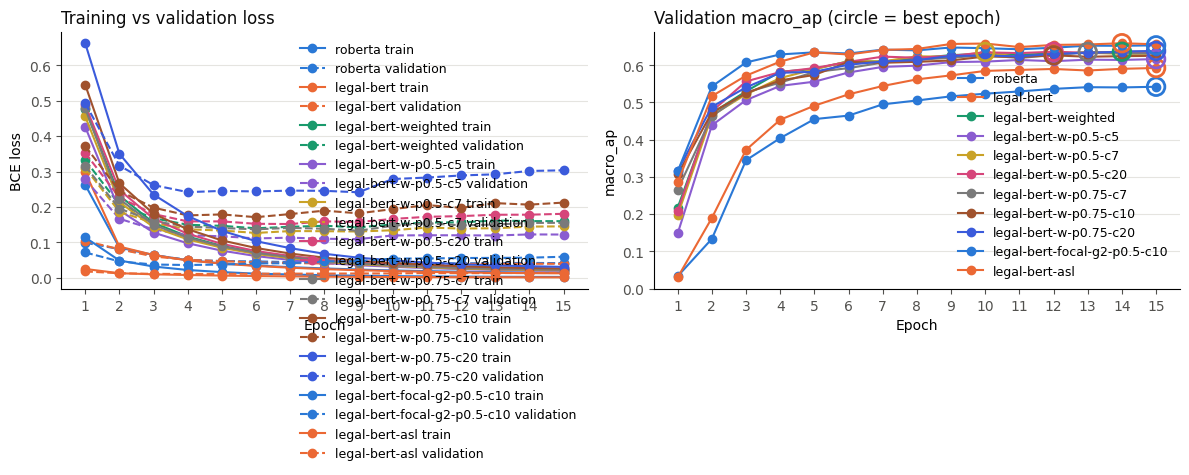

In [ ]:
summaries, histories = {}, {}
for tag in RUNS:
    if os.path.exists(f"{RESULTS_DIR}/{tag}/summary.json"):
        with open(f"{RESULTS_DIR}/{tag}/summary.json") as f:
            summaries[tag] = json.load(f)
        histories[tag] = pd.read_csv(f"{RESULTS_DIR}/{tag}/epoch_history.csv")
assert summaries, "No finished runs found. Run section 6 first."

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
PALETTE = ["#2a78d6", "#eb6834", "#1a9a6c", "#8a5cd0", "#c9a227", "#d6457a", "#2f9fb0", "#7a7a7a", "#a0522d", "#3b5bdb"]
COLORS = {tag: PALETTE[i % len(PALETTE)] for i, tag in enumerate(RUNS)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for tag, h in histories.items():
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", color=COLORS[tag], label=f"{tag} train")
    axes[0].plot(h["epoch"], h["val_loss"], marker="o", linestyle="--", color=COLORS[tag], label=f"{tag} validation")
    axes[1].plot(h["epoch"], h[SELECT_METRIC], marker="o", color=COLORS[tag], label=tag)
    b = summaries[tag]["best_epoch"]
    axes[1].scatter([b], [h.loc[h["epoch"] == b, SELECT_METRIC].iloc[0]], s=160, facecolors="none",
                    edgecolors=COLORS[tag], linewidths=2, zorder=3)
axes[0].set_title("Training vs validation loss", loc="left", color=INK)
axes[0].set_ylabel("BCE loss")
axes[1].set_title(f"Validation {SELECT_METRIC} (circle = best epoch)", loc="left", color=INK)
axes[1].set_ylabel(SELECT_METRIC)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(sorted({e for h in histories.values() for e in h["epoch"]}))
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
if MODE == "smoke":
    fig.suptitle("SMOKE RUN (CPU, tiny subset): checks the pipeline only, the numbers are not meaningful", color="#b3261e", fontsize=10)
plt.tight_layout()
plt.savefig(f"{EXP_DIR}/{EXP_TAG}_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Validation scores per epoch

In [ ]:
table = pd.concat({tag: h.set_index("epoch") for tag, h in histories.items()}, names=["model", "epoch"])
table.round(4)

train_loss  val_loss  macro_ap  micro_ap  \
model          epoch                                             
roberta        1          0.2623    0.0989    0.0333    0.0414   
               2          0.0853    0.0809    0.1337    0.2407   
               3          0.0643    0.0630    0.3449    0.5252   
               4          0.0495    0.0508    0.4043    0.6123   
               5          0.0406    0.0472    0.4553    0.6509   
...                          ...       ...       ...       ...   
legal-bert-asl 11         0.0017    0.0131    0.6490    0.7708   
               12         0.0015    0.0129    0.6547    0.7751   
               13         0.0013    0.0132    0.6558    0.7742   
               14         0.0012    0.0135    0.6593    0.7734   
               15         0.0011    0.0134    0.6563    0.7744   

                      micro_precision  micro_recall  micro_f1  macro_f1  
model          epoch                                                     
roberta        1               0.0000        0.0000    0.0000    0.0000  
               2               0.8667        0.0919    0.1662    0.0590  
               3               0.8576        0.3017    0.4464    0.1804  
               4               0.8370        0.4054    0.5462    0.2618  
               5               0.8191        0.4750    0.6013    0.3255  
...                               ...           ...       ...       ...  
legal-bert-asl 11              0.5402        0.8268    0.6535    0.5812  
               12              0.5821        0.8085    0.6769    0.6016  
               13              0.5703        0.8173    0.6718    0.6017  
               14              0.5693        0.8179    0.6713    0.6065  
               15              0.5838        0.8132    0.6796    0.6132  

[165 rows x 8 columns]

### Best run and epoch
Chosen on validation only (`WINNER_METRIC`). Test columns are filled only for the runs scored in an earlier milestone (RoBERTa, Legal-BERT, weighted Legal-BERT). TF-IDF reference (`experimentation/TF-IDF/03_TF-IDF_model.ipynb`): micro F1 0.591, macro F1 0.517 at 0.5.

In [ ]:
TFIDF_TEST = {"micro_f1": 0.591, "macro_f1": 0.517}   # from experimentation/TF-IDF/03_TF-IDF_model.ipynb

best_tag = max(summaries, key=lambda t: summaries[t]["best_val"][WINNER_METRIC])   # winner: validation only
rows = []
for tag, s in summaries.items():
    run = RUNS[tag]
    test = s.get("test_at_best_epoch", {})       # only present for runs whose test set was scored
    rows.append({"run": tag, "model": run["model"],
                  "loss": (f"{run['loss']} " + " ".join(f"{k}{v}" for k, v in run.items() if k not in ("model", "loss"))) if run.get("loss")
                         else f"weighted p{run['power']} cap{run['cap']}" if run.get("power") is not None else "bce",
                 "best_epoch": s["best_epoch"],
                 "val_macro_ap": s["best_val"]["macro_ap"], "val_macro_f1": s["best_val"]["macro_f1"],
                 "val_micro_f1": s["best_val"]["micro_f1"],
                 "test_micro_f1": test.get("micro_f1"), "test_macro_f1": test.get("macro_f1"),
                 "train_minutes": s["train_minutes"], "chosen": tag == best_tag})
comparison = pd.DataFrame(rows).sort_values(f"val_{WINNER_METRIC}", ascending=False)
comparison = pd.concat([comparison, pd.DataFrame([{"run": "tf-idf baseline", "test_micro_f1": TFIDF_TEST["micro_f1"],
                                                    "test_macro_f1": TFIDF_TEST["macro_f1"]}])]).set_index("run")
comparison.to_csv(f"{EXP_DIR}/{EXP_TAG}_model_comparison.csv")

print(f"Chosen on validation {WINNER_METRIC}: {best_tag} ({summaries[best_tag]['model']}), epoch {summaries[best_tag]['best_epoch']}, "
      f"checkpoint: {summaries[best_tag]['checkpoint']}")
if MODE == "smoke":
    print("SMOKE RUN: the comparison only shows the pipeline works. Re-run on a GPU for real results.")
comparison.round(3)

Chosen on validation macro_f1: legal-bert-focal-g2-p0.5-c10 (nlpaueb/legal-bert-base-uncased), epoch 15, checkpoint: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep/legal-bert-focal-g2-p0.5-c10/best


,model,loss,best_epoch,val_macro_ap,val_macro_f1,val_micro_f1,test_micro_f1,test_macro_f1,train_minutes,chosen
run,,,,,,,,,,
legal-bert-focal-g2-p0.5-c10,legal-bert,focal gamma2 power0.5 cap10,15.0,0.654,0.634,0.725,NaN,NaN,13.9,True
legal-bert-weighted,legal-bert,weighted p0.5 cap10,14.0,0.636,0.626,0.700,0.709,0.658,13.5,False
legal-bert-w-p0.75-c7,legal-bert,weighted p0.75 cap7,13.0,0.636,0.616,0.697,NaN,NaN,13.7,False
legal-bert-w-p0.75-c20,legal-bert,weighted p0.75 cap20,15.0,0.639,0.613,0.679,NaN,NaN,13.8,False
legal-bert-w-p0.5-c5,legal-bert,weighted p0.5 cap5,15.0,0.617,0.611,0.708,NaN,NaN,13.6,False
legal-bert-w-p0.5-c7,legal-bert,weighted p0.5 cap7,10.0,0.636,0.611,0.693,NaN,NaN,13.6,False
legal-bert-w-p0.5-c20,legal-bert,weighted p0.5 cap20,12.0,0.636,0.609,0.685,NaN,NaN,43.1,False
legal-bert-asl,legal-bert,asl gamma_neg4 gamma_pos0 clip0.05,14.0,0.659,0.606,0.671,NaN,NaN,13.6,False
legal-bert-w-p0.75-c10,legal-bert,weighted p0.75 cap10,12.0,0.627,0.604,0.679,NaN,NaN,43.1,False


### Weakest categories on validation (chosen model)
Lowest validation AP first: the categories the model finds hardest.

In [ ]:
per_cat = pd.read_csv(f"{RESULTS_DIR}/{best_tag}/val_per_category.csv", index_col=0)
per_cat.sort_values("val_ap").head(10).round(3)

,val_ap,val_positives
Affiliate License-Licensor,0.011,3
Price Restrictions,0.023,8
Competitive Restriction Exception,0.157,14
Most Favored Nation,0.173,4
Third Party Beneficiary,0.291,9
No-Solicit Of Customers,0.326,8
Volume Restriction,0.347,19
Non-Disparagement,0.385,8
Affiliate License-Licensee,0.395,25
Post-Termination Services,0.477,70


## 8. Contract-level and per-category analysis
No training: these cells use each run's saved validation probabilities (`val_probs.npy`), or its checkpoint if they are missing.

**Contract-level scores.** A contract counts as containing a clause if any of its chunks is labeled (gold) or predicted ≥ 0.5 (prediction). This matches how the risk tool uses the model. (`legal-bert-w-p0.5-c10-dorig-k1.0` is the weighted baseline re-run in the data-variants notebook, so it has contract-level scores.)

In [ ]:
# Contract-level validation scores (no training). A clause counts as present in a contract if any of its chunks is
# labeled (gold) or predicted >= 0.5. Uses each run's saved validation probabilities (val_probs.npy), or its checkpoint if missing.
from sklearn.metrics import precision_recall_fscore_support

def contract_level_scores(titles, y_true, probs, threshold=0.5):
    y_true, probs = np.asarray(y_true), np.asarray(probs)
    df = pd.DataFrame(np.hstack([y_true, probs >= threshold]).astype(int))
    df["title"] = list(titles)
    n = y_true.shape[1]
    agg = df.groupby("title").max()
    gold, pred = agg.iloc[:, :n].to_numpy(), agg.iloc[:, n:2 * n].to_numpy()
    has = gold.sum(axis=0) > 0
    out = {}
    for avg in ["micro", "macro"]:
        p, r, f, _ = precision_recall_fscore_support(gold[:, has], pred[:, has], average=avg, zero_division=0)
        out.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    out["contracts"] = int(len(agg))
    return out

val = prepare_splits("legal-bert")["validation"]
COLS = ["input_ids", "attention_mask", "labels"]

def val_probs_of(name):
    # Validation probabilities of a run: saved file if there is one, else predicted from its checkpoint (and saved), else None
    path, ckpt = f"{RESULTS_DIR}/{name}/val_probs.npy", f"{MODELS_DIR}/{name}/best"
    if os.path.exists(path):
        probs = np.load(path)
        if len(probs) == val.num_rows:
            return probs
    if not os.path.exists(ckpt):
        return None
    model = AutoModelForSequenceClassification.from_pretrained(ckpt)
    args = TrainingArguments(output_dir=f"{MODELS_DIR}/tmp_eval", per_device_eval_batch_size=32,
                             bf16=USE_BF16, fp16=USE_FP16, report_to="none")
    trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tokenizers["legal-bert"]))
    probs = sigmoid(trainer.predict(val.select_columns(COLS)).predictions)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    np.save(path, probs)
    del trainer, model; gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
    return probs

rows = {}
for name in ["legal-bert-w-p0.5-c10-dorig-k1.0", "legal-bert-focal-g2-p0.5-c10", "legal-bert-asl"]:
    probs = val_probs_of(name)
    if probs is None:
        print("No saved probabilities or checkpoint for", name, "- skipped"); continue
    s = contract_level_scores(val["title"], val["labels"], probs)
    rows[name] = {"contract_macro_f1": s["macro_f1"], "contract_micro_f1": s["micro_f1"],
                  "contract_macro_precision": s["macro_precision"], "contract_macro_recall": s["macro_recall"],
                  "contracts": s["contracts"]}
pd.DataFrame(rows).T.round(3)

,contract_macro_f1,contract_micro_f1,contract_macro_precision,contract_macro_recall,contracts
legal-bert-w-p0.5-c10-dorig-k1.0,0.771,0.859,0.742,0.839,61.0
legal-bert-focal-g2-p0.5-c10,0.767,0.870,0.764,0.779,61.0
legal-bert-asl,0.759,0.850,0.685,0.901,61.0


In [ ]:
# Validation probabilities of each run, saved with the results so later analyses need no GPU
VAL_RUNS = ["legal-bert-w-p0.5-c10-dorig-k1.0", "legal-bert-focal-g2-p0.5-c10", "legal-bert-asl", "legal-bert-focal-optuna"]
y_val = np.array(val["labels"]).astype(int)
VAL_PROBS = {}
for name in VAL_RUNS:
    probs = val_probs_of(name)
    if probs is None:
        print("No saved probabilities or checkpoint for", name, "- skipped")
    else:
        VAL_PROBS[name] = probs
print({k: v.shape for k, v in VAL_PROBS.items()})

{'legal-bert-w-p0.5-c10-dorig-k1.0': (2069, 41), 'legal-bert-focal-g2-p0.5-c10': (2069, 41), 'legal-bert-asl': (2069, 41), 'legal-bert-focal-optuna': (2069, 41)}


### Per-category F1
F1 at 0.5 for each category on validation, weakest first. A handful of rare categories pull the macro average down.

In [ ]:
# Per-category F1 at 0.5 on validation, weakest first (sorted by the focal model)
from sklearn.metrics import f1_score
if not VAL_PROBS:
    print("No validation probabilities found; nothing to show.")
else:
    REF = "legal-bert-focal-g2-p0.5-c10" if "legal-bert-focal-g2-p0.5-c10" in VAL_PROBS else next(iter(VAL_PROBS))
    has = y_val.sum(0) > 0
    per_cat = pd.DataFrame({"val_positives": y_val.sum(0)}, index=CATEGORIES)
    for name, p in VAL_PROBS.items():
        per_cat[name] = [f1_score(y_val[:, j], p[:, j] >= 0.5, zero_division=0) if has[j] else np.nan
                         for j in range(len(CATEGORIES))]
    per_cat = per_cat.sort_values(REF)
    print("Macro F1 at 0.5 (should match section 7):", per_cat.drop(columns="val_positives").mean().round(3).to_dict())
    f = per_cat[REF].dropna()
    for k in [5, 10]:
        print(f"{REF}: macro F1 without the {k} weakest categories = {f.iloc[k:].mean():.3f}")
    display(per_cat.round(3))

Macro F1 at 0.5 (should match section 7): {'legal-bert-w-p0.5-c10-dorig-k1.0': 0.623, 'legal-bert-focal-g2-p0.5-c10': 0.634, 'legal-bert-asl': 0.606, 'legal-bert-focal-optuna': 0.662}
Focal: macro F1 without the 5 weakest categories = 0.704
Focal: macro F1 without the 10 weakest categories = 0.744


,val_positives,legal-bert-w-p0.5-c10-dorig-k1.0,legal-bert-focal-g2-p0.5-c10,legal-bert-asl,legal-bert-focal-optuna
Affiliate License-Licensor,3,0.000,0.000,0.000,0.000
Most Favored Nation,4,0.250,0.000,0.333,0.800
Price Restrictions,8,0.200,0.000,0.000,0.200
Competitive Restriction Exception,14,0.205,0.270,0.179,0.286
No-Solicit Of Customers,8,0.316,0.353,0.300,0.267
Volume Restriction,19,0.278,0.353,0.361,0.412
Post-Termination Services,70,0.439,0.457,0.488,0.525
Affiliate License-Licensee,25,0.474,0.479,0.478,0.500
Exclusivity,62,0.521,0.493,0.503,0.651
Joint Ip Ownership,20,0.439,0.500,0.435,0.500


### One global threshold
The same threshold for all 41 categories, chosen on validation. A better threshold than 0.5 gives at most a small gain, so the pipeline keeps 0.5.

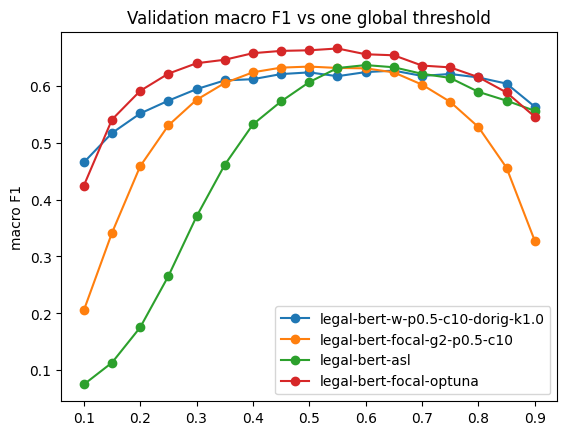

,macro_f1_at_0.5,best_threshold,macro_f1_at_best,contract_macro_f1_at_0.5,contract_macro_f1_at_best
legal-bert-w-p0.5-c10-dorig-k1.0,0.623,0.65,0.626,0.771,0.773
legal-bert-focal-g2-p0.5-c10,0.634,0.50,0.634,0.767,0.767
legal-bert-asl,0.606,0.60,0.636,0.759,0.767
legal-bert-focal-optuna,0.662,0.55,0.665,0.787,0.788


In [ ]:
# One threshold for all 41 categories, chosen on validation. Compares chunk- and contract-level at 0.5 vs the best threshold.
if not VAL_PROBS:
    print("No validation probabilities found; nothing to show.")
else:
    thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)
    sweep = pd.DataFrame({name: [multilabel_scores(y_val, p, t)["macro_f1"] for t in thresholds]
                          for name, p in VAL_PROBS.items()}, index=thresholds)
    best_t = sweep.idxmax()
    summary = pd.DataFrame({
        "macro_f1_at_0.5": sweep.loc[0.5], "best_threshold": best_t, "macro_f1_at_best": sweep.max(),
        "contract_macro_f1_at_0.5": [contract_level_scores(val["title"], y_val, VAL_PROBS[n], 0.5)["macro_f1"] for n in sweep.columns],
        "contract_macro_f1_at_best": [contract_level_scores(val["title"], y_val, VAL_PROBS[n], best_t[n])["macro_f1"] for n in sweep.columns]})
    sweep.plot(marker="o", title="Validation macro F1 vs one global threshold", ylabel="macro F1")
    plt.show()
    display(summary.round(3))

## 9. Hyperparameter tuning with Optuna
Tunes the learning rate, number of epochs, warmup and weight decay of the focal setup (Legal-BERT + focal loss γ = 2 + class weights p0.5 cap 10). Each trial is scored like every other run: best epoch on validation macro AP, objective = validation macro F1 at 0.5. Optuna's TPE sampler picks the next settings from the earlier trials; the median pruner stops weak trials early. The best trial is saved as the run `legal-bert-focal-optuna`.

**`RUN_OPTUNA = False` (default):** the saved study is loaded and shown; nothing is trained. **`True`:** the remaining trials run (about 2.5 hours on an A100 for 8 trials). The study database is copied to Drive after every trial, so a disconnect loses at most the running trial.

In [ ]:
# ===== Hyperparameter tuning with Optuna: Legal-BERT + focal loss (gamma 2) + weights p0.5-c10 =====
# Each trial trains the focal setup with different settings and is scored like every other run:
# best epoch chosen on validation SELECT_METRIC, objective = validation macro F1 at that epoch (threshold 0.5).
import dataclasses, subprocess, sys
try:
    import optuna
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna"], check=True)
    import optuna
from transformers import TrainerCallback

OPTUNA = dict(
    study_name="focal-legal-bert",   # change the name to start a fresh study
    n_trials=8 if MODE == "full" else 2,   # total finished + pruned trials wanted (smoke: 2 tiny trials)
    base=dict(model="legal-bert", loss="focal", gamma=2, power=0.5, cap=10),  # fixed unless tuned below
    tune_gamma_cap=False,            # True: also search focal gamma (1, 2, 3) and the weight cap (5, 10, 20)
    epochs=(8, 20) if MODE == "full" else (2, 3),
    first_trial_is_current=True,     # trial 0 = the current settings (lr 2e-5, 15 epochs, ...): a check that the loop reproduces ~0.634
    disconnect_when_done=False,       # full mode only: release the GPU when the study is finished
)

TAG = OPTUNA["base"]["model"]
STUDY_DIR = f"{RESULTS_DIR}/optuna/{OPTUNA['study_name']}"          # on Drive: trial results + study database
LOCAL_TMP = "/content/optuna_tmp" if IN_COLAB else "../../../models/optuna_tmp"   # trial checkpoints (local disk, deleted after each trial)
BEST_RUN = f"{TAG}-focal-optuna"                                     # the best trial is saved as a normal run with this name
os.makedirs(STUDY_DIR, exist_ok=True)
print("Study folder:", STUDY_DIR)

Study folder: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/results/training/15ep/optuna/focal-legal-bert


In [ ]:
if "contract_level_scores" not in globals():   # defined in the contract-level cell above; repeated here so this cell can run alone
    def contract_level_scores(titles, y_true, probs, threshold=0.5):
        y_true, probs = np.asarray(y_true), np.asarray(probs)
        df = pd.DataFrame(np.hstack([y_true, probs >= threshold]).astype(int))
        df["title"] = list(titles)
        n = y_true.shape[1]
        agg = df.groupby("title").max()
        gold, pred = agg.iloc[:, :n].to_numpy(), agg.iloc[:, n:2 * n].to_numpy()
        has = gold.sum(axis=0) > 0
        out = {}
        for avg in ["micro", "macro"]:
            p, r, f, _ = precision_recall_fscore_support(gold[:, has], pred[:, has], average=avg, zero_division=0)
            out.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
        out["contracts"] = int(len(agg))
        return out

# Tokenize once for all trials (the data does not change between trials)
OPT_SPLITS = prepare_splits(TAG)
COLS = ["input_ids", "attention_mask", "labels"]
print({k: v.num_rows for k, v in OPT_SPLITS.items()})

{'train': 12112, 'validation': 2069, 'test': 2898}


In [ ]:
def suggest(trial):
    """The search space. Trial 0 can be the current settings (enqueued below)."""
    p = dict(OPTUNA["base"])
    p["learning_rate"] = trial.suggest_float("learning_rate", 1e-5, 6e-5, log=True)
    p["num_epochs"] = trial.suggest_int("num_epochs", *OPTUNA["epochs"])
    p["warmup_ratio"] = trial.suggest_float("warmup_ratio", 0.0, 0.2)
    p["weight_decay"] = trial.suggest_float("weight_decay", 0.0, 0.1)
    if OPTUNA["tune_gamma_cap"]:
        p["gamma"] = trial.suggest_categorical("gamma", [1, 2, 3])
        p["cap"] = trial.suggest_categorical("cap", [5, 10, 20])
    return p

class ReportToOptuna(TrainerCallback):
    """After each epoch: report validation macro F1 to Optuna and stop the trial early if Optuna prunes it."""
    def __init__(self, trial):
        self.trial, self.pruned = trial, False
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        self.trial.report(metrics["eval_macro_f1"], step=round(state.epoch))
        if self.trial.should_prune():
            self.pruned = True
            control.should_training_stop = True

def save_study():
    shutil.copy(LOCAL_DB, DRIVE_DB)   # keep the Drive copy current, so a disconnect loses at most the running trial

In [ ]:
def objective(trial):
    p = suggest(trial)
    print(f"\n[trial {trial.number}] " + ", ".join(f"{k}={v:.2g}" if isinstance(v, float) else f"{k}={v}"
                                                    for k, v in p.items() if k not in ("model", "loss")))
    set_seed(SEED)
    tmp_dir = f"{LOCAL_TMP}/trial-{trial.number}"
    args = dataclasses.replace(training_args(tmp_dir), num_train_epochs=p["num_epochs"], learning_rate=p["learning_rate"],
                               warmup_ratio=p["warmup_ratio"], weight_decay=p["weight_decay"])
    model = AutoModelForSequenceClassification.from_pretrained(
        MODELS[TAG], num_labels=len(CATEGORIES), problem_type="multi_label_classification",
        id2label=dict(enumerate(CATEGORIES)), label2id={c: i for i, c in enumerate(CATEGORIES)})
    reporter = ReportToOptuna(trial)
    trainer = LossTrainer(model=model, args=args,
                          train_dataset=OPT_SPLITS["train"].select_columns(COLS),
                          eval_dataset=OPT_SPLITS["validation"].select_columns(COLS),
                          data_collator=DataCollatorWithPadding(tokenizers[TAG]), compute_metrics=compute_metrics,
                          callbacks=[reporter], run=p, pos_weight=compute_pos_weight(p["power"], p["cap"]))
    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60
    history = epoch_history(trainer.state.log_history)
    best = history.loc[history[SELECT_METRIC].idxmax()]          # same epoch rule as every other run
    trial_dir = f"{STUDY_DIR}/trial-{trial.number}"
    os.makedirs(trial_dir, exist_ok=True)
    history.to_csv(f"{trial_dir}/epoch_history.csv", index=False)
    summary = {"trial": trial.number, "params": p, "pruned": reporter.pruned, "best_epoch": int(best["epoch"]),
               "epochs_run": int(history["epoch"].max()), "best_val": {k: float(v) for k, v in best.items() if k != "epoch"},
               "train_minutes": round(minutes, 1)}

    if not reporter.pruned:
        # Contract-level score of the best epoch (load_best_model_at_end put it back into trainer.model)
        val_probs = sigmoid(trainer.predict(OPT_SPLITS["validation"].select_columns(COLS)).predictions)
        y_val = np.array(OPT_SPLITS["validation"]["labels"])
        summary["val_contract"] = {k: float(v) for k, v in
                                   contract_level_scores(OPT_SPLITS["validation"]["title"], y_val, val_probs).items()}
        trial.set_user_attr("contract_macro_f1", summary["val_contract"]["macro_f1"])
        # Keep only the best trial's model (saved as a normal run, so section 7 and score_test_once can use it)
        previous = [t.value for t in trial.study.get_trials(deepcopy=False, states=[optuna.trial.TrialState.COMPLETE])]
        if not previous or best["macro_f1"] > max(previous):
            best_dir = f"{MODELS_DIR}/{BEST_RUN}/best"
            trainer.save_model(best_dir)
            tokenizers[TAG].save_pretrained(best_dir)
            res_dir = f"{RESULTS_DIR}/{BEST_RUN}"
            os.makedirs(res_dir, exist_ok=True)
            history.to_csv(f"{res_dir}/epoch_history.csv", index=False)
            pd.DataFrame({"val_ap": [average_precision_score(y_val[:, j], val_probs[:, j]) if y_val[:, j].any() else np.nan
                                     for j in range(len(CATEGORIES))],
                          "val_positives": y_val.sum(0).astype(int)}, index=CATEGORIES).to_csv(f"{res_dir}/val_per_category.csv")
            run_summary = {"model": MODELS[TAG], "tag": TAG, "run": BEST_RUN, "mode": MODE, "best_epoch": int(best["epoch"]),
                           "select_metric": SELECT_METRIC, "best_val": summary["best_val"], "val_contract": summary["val_contract"],
                           "loss": {"type": "focal", **{k: v for k, v in p.items() if k not in ("model", "loss")}},
                           "train_minutes": round(minutes, 1), "device": torch.cuda.get_device_name(0) if HAS_GPU else "cpu",
                           "config": {**CFG, "num_epochs": p["num_epochs"], "learning_rate": p["learning_rate"],
                                      "warmup_ratio": p["warmup_ratio"], "weight_decay": p["weight_decay"]},
                           "text_cleanup": TEXT_CLEANUP[TAG], "train_chunks": OPT_SPLITS["train"].num_rows,
                           "checkpoint": best_dir, "optuna_trial": trial.number}
            with open(f"{res_dir}/summary.json", "w") as f:
                json.dump(run_summary, f, indent=1)
            with open(f"{best_dir}/training_info.json", "w") as f:
                json.dump({**run_summary, "categories": CATEGORIES}, f, indent=1)
            print(f"[trial {trial.number}] new best: saved as run '{BEST_RUN}'")
    with open(f"{trial_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)

    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
    shutil.rmtree(tmp_dir, ignore_errors=True)    # trial checkpoints are not kept

    contract = f", contract-level {summary['val_contract']['macro_f1']:.3f}" if "val_contract" in summary else ""
    print(f"[trial {trial.number}] {'PRUNED after' if reporter.pruned else 'done:'} {summary['epochs_run']} epochs, "
          f"{minutes:.1f} min | best epoch {summary['best_epoch']}: val macro F1 {best['macro_f1']:.3f}, "
          f"macro AP {best['macro_ap']:.3f}{contract}")
    if reporter.pruned:
        raise optuna.TrialPruned()
    return float(best["macro_f1"])

In [ ]:
# Study database: worked on locally (fast, safe), copied to Drive after every trial, restored from Drive if it exists
os.makedirs(LOCAL_TMP, exist_ok=True)
LOCAL_DB, DRIVE_DB = f"{LOCAL_TMP}/{OPTUNA['study_name']}-{MODE}.db", f"{STUDY_DIR}/study.db"
if os.path.exists(DRIVE_DB) and not os.path.exists(LOCAL_DB):
    shutil.copy(DRIVE_DB, LOCAL_DB)
study = optuna.create_study(study_name=OPTUNA["study_name"], storage=f"sqlite:///{os.path.abspath(LOCAL_DB)}",
                            load_if_exists=True, direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=5))
if RUN_OPTUNA and OPTUNA["first_trial_is_current"] and not study.trials:
    study.enqueue_trial({"learning_rate": CFG["learning_rate"], "num_epochs": CFG["num_epochs"],
                         "warmup_ratio": CFG["warmup_ratio"], "weight_decay": CFG["weight_decay"]})
finished = [t for t in study.trials if t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)]
remaining = OPTUNA["n_trials"] - len(finished)
print(f"Study '{OPTUNA['study_name']}': {len(finished)} trials already finished"
      + (f", {max(remaining, 0)} to run." if RUN_OPTUNA else "."))
if not RUN_OPTUNA:
    print("RUN_OPTUNA is False: showing the saved study, no trials are run.")
try:
    if RUN_OPTUNA and remaining > 0:
        study.optimize(objective, n_trials=remaining, callbacks=[lambda s, t: save_study()], gc_after_trial=True)
except Exception:
    save_study()                      # keep the finished trials on Drive
    if IN_COLAB and MODE == "full":
        from google.colab import runtime
        runtime.unassign()            # error overnight: release the GPU instead of idling
    raise
if RUN_OPTUNA:
    save_study()

[I 2026-11-17 16:23:13,058] Using an existing study with `study_name='focal-legal-bert'` instead of creating a new one.


Study 'focal-legal-bert': 8 trials already finished, 0 to run.


In [ ]:
# Results: one row per trial, best first
completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
if not completed:
    print("No finished trials found. Set RUN_OPTUNA = True to run the study.")
else:
    trials = study.trials_dataframe(attrs=("number", "value", "params", "state", "user_attrs"))
    trials = trials.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", "")).rename(columns={"value": "val_macro_f1"})
    trials = trials.sort_values("val_macro_f1", ascending=False).set_index("number")
    if RUN_OPTUNA:
        trials.to_csv(f"{STUDY_DIR}/trials.csv")
    trials["learning_rate"] = trials["learning_rate"].map("{:.1e}".format)
    bt = study.best_trial
    # Register the best trial as a normal run, so section 7 (re-run it) can find it
    RUNS[BEST_RUN] = {**OPTUNA["base"], **{k: float(f"{v:.3g}") if isinstance(v, float) else v for k, v in bt.params.items()}}
    print(f"\nBest trial: {bt.number} | val macro F1 {study.best_value:.3f} | contract-level "
          f"{bt.user_attrs.get('contract_macro_f1', float('nan')):.3f} | params {bt.params}")
    print(f"Saved as run '{BEST_RUN}'. Reference (focal, 15 epochs, lr 2e-5): val macro F1 0.634, contract-level 0.767.")
    display(trials.round(4))

if RUN_OPTUNA and OPTUNA["disconnect_when_done"] and IN_COLAB and MODE == "full":
    from google.colab import runtime
    runtime.unassign()


Best trial: 5 | val macro F1 0.662 | contract-level 0.787 | params {'learning_rate': 5.833508124642314e-05, 'num_epochs': 20, 'warmup_ratio': 0.027812682368409187, 'weight_decay': 0.09767852842594692}
Saved as run 'legal-bert-focal-optuna'. Reference (focal, 15 epochs, lr 2e-5): val macro F1 0.634, contract-level 0.767.


,val_macro_f1,learning_rate,num_epochs,warmup_ratio,weight_decay,state,contract_macro_f1
number,,,,,,,
5,0.6622,5.8e-05,20,0.0278,0.0977,COMPLETE,0.7869
6,0.6505,4.5e-05,10,0.0275,0.0221,COMPLETE,0.7891
3,0.6442,2.9e-05,17,0.0041,0.0970,COMPLETE,0.7727
1,0.6406,2.0e-05,20,0.1464,0.0599,COMPLETE,0.7878
4,0.6244,4.2e-05,12,0.0136,0.0748,COMPLETE,0.7737
0,0.6243,2.0e-05,15,0.1000,0.0100,COMPLETE,0.7564
2,0.5848,1.3e-05,10,0.0116,0.0866,COMPLETE,0.7223
7,0.5374,5.9e-05,16,0.1399,0.0738,PRUNED,NaN


### Seed check
The best settings retrained with seed 43 instead of 42. If the score holds up, the gain is not luck of one run. `RUN_SEED_CHECK = False` (default) shows the saved result.

In [ ]:
# Seed check: re-train the best Optuna settings with a different random seed. Does the result hold up?
CHECK_SEED = 43
CHECK_RUN = f"{TAG}-focal-optuna-seed{CHECK_SEED}"
if RUN_SEED_CHECK and completed:
    saved = (SEED, BEST_RUN, STUDY_DIR)
    SEED = CHECK_SEED                                              # different random start (classifier init, data order)
    BEST_RUN = CHECK_RUN                                           # saved under its own name: the Optuna winner is not overwritten
    STUDY_DIR = f"{RESULTS_DIR}/optuna/seed-check-{CHECK_SEED}"   # its own results folder
    os.makedirs(STUDY_DIR, exist_ok=True)
    check = optuna.create_study(direction="maximize")             # a one-trial study, kept in memory only
    check.enqueue_trial(study.best_trial.params)                  # exactly the best trial's settings
    check.optimize(objective, n_trials=1)
    SEED, BEST_RUN, STUDY_DIR = saved
    print(f"\nSeed {CHECK_SEED}: val macro F1 {check.best_value:.3f}, contract-level {check.best_trial.user_attrs['contract_macro_f1']:.3f}"
          f"  |  Optuna winner (seed 42): {study.best_value:.3f}, contract-level {study.best_trial.user_attrs['contract_macro_f1']:.3f}")
elif os.path.exists(f"{RESULTS_DIR}/{CHECK_RUN}/summary.json"):
    with open(f"{RESULTS_DIR}/{CHECK_RUN}/summary.json") as f:
        s = json.load(f)
    print(f"Seed {CHECK_SEED} (saved): val macro F1 {s['best_val']['macro_f1']:.3f}, macro AP {s['best_val']['macro_ap']:.3f}, "
          f"contract-level {s['val_contract']['macro_f1']:.3f}, best epoch {s['best_epoch']}")
else:
    print("Seed check not run: set RUN_SEED_CHECK = True (about 18 minutes on an A100).")

[I 2026-11-17 16:23:13,705] A new study created in memory with name: no-name-51317fcc-a1fc-488c-bb95-74d221a90fcb



[trial 0] gamma=2, power=0.5, cap=10, learning_rate=5.8e-05, num_epochs=20, warmup_ratio=0.028, weight_decay=0.098


pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Epoch,Training Loss,Validation Loss,Macro Ap,Micro Ap,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Categories Scored
1,0.073700,0.043581,0.520566,0.656645,0.399756,0.773129,0.527013,0.365725,0.627104,0.446345,41
2,0.033000,0.039762,0.588944,0.670507,0.390549,0.808486,0.526679,0.409192,0.729429,0.493459,41
3,0.021400,0.036765,0.629071,0.733842,0.472858,0.816146,0.598789,0.450393,0.722237,0.537021,41
4,0.014400,0.038389,0.626417,0.737797,0.459065,0.816146,0.587611,0.437503,0.734855,0.532912,41
5,0.010200,0.041001,0.634343,0.732506,0.515846,0.796111,0.626043,0.485892,0.709608,0.557614,41
6,0.007700,0.046022,0.643992,0.747919,0.554048,0.794343,0.652785,0.519701,0.719226,0.588891,41
7,0.005400,0.050252,0.651449,0.740867,0.579451,0.784325,0.666500,0.553742,0.696046,0.599441,41
8,0.004200,0.055021,0.651446,0.758532,0.631250,0.773718,0.695261,0.572804,0.690849,0.617938,41
9,0.003500,0.053089,0.669649,0.751792,0.582427,0.789039,0.670170,0.563586,0.713144,0.616867,41
10,0.002600,0.059556,0.658720,0.758068,0.612207,0.786093,0.688338,0.560386,0.700217,0.612993,41


[trial 0] new best: saved as run 'legal-bert-focal-optuna-seed43'


[I 2026-11-17 16:41:26,130] Trial 0 finished with value: 0.6540897222832939 and parameters: {'learning_rate': 5.833508124642314e-05, 'num_epochs': 20, 'warmup_ratio': 0.027812682368409187, 'weight_decay': 0.09767852842594692}. Best is trial 0 with value: 0.6540897222832939.


[trial 0] done: 20 epochs, 18.1 min | best epoch 13: val macro F1 0.654, macro AP 0.677, contract-level 0.796

Seed 43: val macro F1 0.654, contract-level 0.796  |  Optuna winner (seed 42): 0.662, contract-level 0.787


## 10. Files saved
| File | In git | Contents |
|---|---|---|
| `results/training/15ep/<run name>/summary.json` | Yes | Best epoch, validation scores (chunk-level; contract-level where computed), loss settings |
| `results/training/15ep/<run name>/epoch_history.csv` | Yes | Loss and validation scores per epoch |
| `results/training/15ep/<run name>/val_per_category.csv` | Yes | Validation AP per category |
| `results/training/15ep/experiments/loss_and_tuning_model_comparison.csv`, `loss_and_tuning_loss_curves.png` | Yes | This notebook's comparison table and loss/AP plot |
| `results/training/15ep/optuna/` | Yes | Optuna study database (`study.db`), `trials.csv`, one folder per trial |
| `results/training/15ep/<run name>/val_probs.npy` | Yes | Validation probabilities (section 8) |
| `models/training/15ep/<run name>/best/` | No (~0.5 GB each) | Best checkpoint, tokenizer, `training_info.json` (Google Drive only) |

On Colab these are under `MyDrive/Accenture-1H-contract-review-challenge/`; smoke runs go to `models/training_smoke/`. The test set is not scored here: the final model is scored once in `notebooks/pipeline/05_model_training_and_selection.ipynb`.

In [ ]:
# Results are saved to Google Drive during the run; download them from there to commit them
if IN_COLAB and MODE == "full":
    print(f"Results are on Google Drive: {RESULTS_DIR}")
    print(f"Download the run folders you trained (and experiments/) and put them in results/training/{RUN_NAME}/ in the repo.")
else:
    print("Nothing to download here." if not IN_COLAB else "Smoke run: nothing worth downloading.")

In [ ]:
# Release the GPU when the notebook has finished (full mode on Colab only). The outputs stay visible.
if IN_COLAB and MODE == "full":
    from google.colab import runtime
    runtime.unassign()

## 11. Results and limitations
**Validation results** (61 contracts; chunk-level = per 512-token chunk, contract-level = clause found anywhere in the contract)

| Run | Chunk-level macro F1 | Macro AP | Contract-level macro F1 |
|---|---|---|---|
| RoBERTa, plain BCE | 0.512 | 0.542 | – |
| Legal-BERT, plain BCE | 0.532 | 0.593 | – |
| Legal-BERT, class weights (8 settings of power and cap) | 0.604–0.626 | 0.617–0.639 | 0.771 (p0.5 cap10) |
| Focal loss (γ = 2) + class weights | 0.634 | 0.654 | 0.767 |
| Asymmetric loss | 0.606 (0.636 at threshold 0.6) | 0.659 | 0.759 |
| **Focal + class weights, tuned with Optuna** (lr 5.8e-5, 20 epochs) | **0.662** | **0.698** | **0.787** |
| Same settings, seed 43 | 0.654 | 0.677 | 0.796 |

All runs before Optuna used learning rate 2e-5 and 15 epochs.

**Findings**
- Legal-BERT beat RoBERTa, and class weights gave the first large gain (+0.09 macro F1).
- The 8 weightings, focal loss and ASL all landed within about ±0.015 of each other: about the size of run-to-run noise. Their macro AP stayed at 0.62–0.66, so they mostly moved the precision/recall balance.
- Tuning was the only further clear gain: a higher learning rate and longer training raised macro AP to about 0.69. The seed check confirmed it (0.654–0.662 chunk-level, 0.787–0.796 contract-level).
- One global threshold barely helps (best 0.5–0.65), so the pipeline keeps 0.5.

**Limitations**
- Every choice, including 8 Optuna trials, was made on the same validation set, so validation scores are somewhat optimistic. The test set is scored once, in the pipeline.
- Run-to-run noise is about ±0.01, so small differences between runs are not meaningful.
- Rare categories set the ceiling: Affiliate License-Licensor (3 validation examples) still scores 0, and macro F1 without the 5 weakest categories is about 0.72.
- Validation loss rises after about epoch 3 while F1 and AP keep improving: the model is overconfident and should be calibrated before its probabilities are used as confidence scores.